In [18]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns

In [19]:
from imblearn.over_sampling import SMOTE

from imblearn.pipeline import Pipeline

In [20]:
import pandas as pd

classification_df = pd.read_csv(
    "../Data/processed/classification_clean.csv"
)

classification_df.shape

(938599, 24)

In [21]:
X_class = classification_df.drop(
    "pha",
    axis=1
)

y_class = classification_df["pha"]

In [22]:
from sklearn.model_selection import train_test_split

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

In [23]:
import numpy as np

num_features_class = X_train_class.select_dtypes(
    include=np.number
).columns.tolist()

cat_features_class = X_train_class.select_dtypes(
    include="object"
).columns.tolist()

In [24]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

In [25]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

In [26]:
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

In [27]:
preprocessor_class = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            num_features_class
        ),
        (
            "cat",
            categorical_transformer,
            cat_features_class
        )
    ]
)

In [28]:
type(preprocessor_class)

sklearn.compose._column_transformer.ColumnTransformer

In [29]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression

In [30]:
logistic_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_class
        ),

        (
            "smote",
            SMOTE(random_state=42)
        ),

        (
            "model",
            LogisticRegression(
                max_iter=1000
            )
        )
    ]
)

In [31]:
y_train_class.value_counts()


pha
N    749226
Y      1653
Name: count, dtype: int64

In [32]:
X_sample = X_train_class.sample(
    100000,
    random_state=42
)

y_sample = y_train_class.loc[
    X_sample.index
]

In [34]:
logistic_pipeline.fit(
    X_sample,
    y_sample
)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](2,)","['N','Y']"
feature_names_in_,"ndarray[object](23,)","['H','diameter','albedo',...,'w_cos','ma_sin','ma_cos']"
n_features_in_,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [35]:
y_pred_lr = logistic_pipeline.predict(
    X_test_class
)

In [36]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test_class,
        y_pred_lr
    )
)

              precision    recall  f1-score   support

           N       1.00      0.99      0.99    187307
           Y       0.16      0.99      0.28       413

    accuracy                           0.99    187720
   macro avg       0.58      0.99      0.64    187720
weighted avg       1.00      0.99      0.99    187720



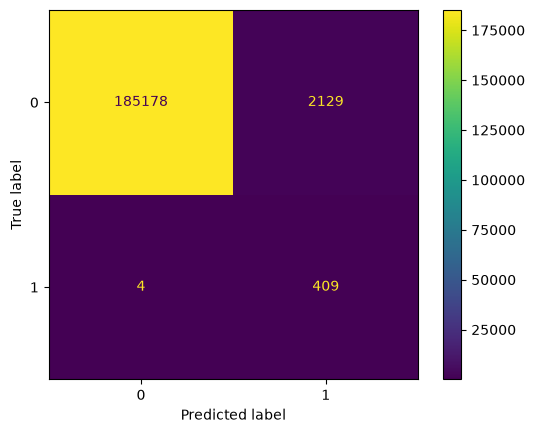

In [37]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

cm = confusion_matrix(
    y_test_class,
    y_pred_lr
)

ConfusionMatrixDisplay(
    confusion_matrix=cm
).plot()

plt.show()

In [38]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(
    y_test_class,
    y_pred_lr
)

print("Accuracy:", acc)

Accuracy: 0.988637332196889


In [39]:
from sklearn.metrics import precision_score

precision = precision_score(
    y_test_class,
    y_pred_lr,
    pos_label="Y"
)

print("Precision:", precision)

Precision: 0.161150512214342


In [40]:
from sklearn.metrics import recall_score

recall = recall_score(
    y_test_class,
    y_pred_lr,
    pos_label="Y"
)

print("Recall:", recall)

Recall: 0.9903147699757869


In [41]:
from sklearn.metrics import f1_score

f1 = f1_score(
    y_test_class,
    y_pred_lr,
    pos_label="Y"
)

print("F1 Score:", f1)

F1 Score: 0.27719417146729924


In [42]:
from sklearn.metrics import roc_auc_score

In [43]:
y_prob_lr = logistic_pipeline.predict_proba(
    X_test_class
)[:, 1]

In [44]:
y_true = (
    y_test_class == "Y"
).astype(int)

In [45]:
roc_auc = roc_auc_score(
    y_true,
    y_prob_lr
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.9969523690251186


In [46]:
rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_class
        ),

        (
            "smote",
            SMOTE(random_state=42)
        ),

        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [47]:
rf_pipeline.fit(
    X_sample,
    y_sample
)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](2,)","['N','Y']"
feature_names_in_,"ndarray[object](23,)","['H','diameter','albedo',...,'w_cos','ma_sin','ma_cos']"
n_features_in_,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [48]:
y_pred_rf = rf_pipeline.predict(
    X_test_class
)

In [49]:
print(
    classification_report(
        y_test_class,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

           N       1.00      1.00      1.00    187307
           Y       0.43      0.70      0.53       413

    accuracy                           1.00    187720
   macro avg       0.71      0.85      0.76    187720
weighted avg       1.00      1.00      1.00    187720



In [50]:
gb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor_class
        ),

        (
            "smote",
            SMOTE(
                random_state=42
            )
        ),

        (
            "model",
            GradientBoostingClassifier(
                random_state=42
            )
        )
    ]
)

In [51]:
gb_pipeline.fit(
    X_sample,
    y_sample
)

,steps,"[('preprocessor', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[object](2,)","['N','Y']"
feature_names_in_,"ndarray[object](23,)","['H','diameter','albedo',...,'w_cos','ma_sin','ma_cos']"
n_features_in_,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3


In [52]:
y_pred_gb = gb_pipeline.predict(
    X_test_class
)

In [53]:
print(
    classification_report(
        y_test_class,
        y_pred_gb
    )
)

              precision    recall  f1-score   support

           N       1.00      1.00      1.00    187307
           Y       0.39      0.91      0.54       413

    accuracy                           1.00    187720
   macro avg       0.69      0.95      0.77    187720
weighted avg       1.00      1.00      1.00    187720



In [54]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({

    "Model":[
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],

    "Precision":[
        precision_score(y_test_class,y_pred_lr,pos_label='Y'),
        precision_score(y_test_class,y_pred_rf,pos_label='Y'),
        precision_score(y_test_class,y_pred_gb,pos_label='Y')
    ],

    "Recall":[
        recall_score(y_test_class,y_pred_lr,pos_label='Y'),
        recall_score(y_test_class,y_pred_rf,pos_label='Y'),
        recall_score(y_test_class,y_pred_gb,pos_label='Y')
    ],

    "F1 Score":[
        f1_score(y_test_class,y_pred_lr,pos_label='Y'),
        f1_score(y_test_class,y_pred_rf,pos_label='Y'),
        f1_score(y_test_class,y_pred_gb,pos_label='Y')
    ]
})

comparison

,Model,Precision,Recall,F1 Score
0,Logistic Regression,0.161151,0.990315,0.277194
1,Random Forest,0.426667,0.697337,0.529412
2,Gradient Boosting,0.387064,0.912833,0.543619


In [55]:
comparison["Precision"] = (
    comparison["Precision"] * 100
).round(2)

comparison["Recall"] = (
    comparison["Recall"] * 100
).round(2)

comparison["F1 Score"] = (
    comparison["F1 Score"] * 100
).round(2)

comparison

,Model,Precision,Recall,F1 Score
0,Logistic Regression,16.12,99.03,27.72
1,Random Forest,42.67,69.73,52.94
2,Gradient Boosting,38.71,91.28,54.36


In [47]:
import joblib

joblib.dump(
    gb_pipeline,
    "../models/pha_classifier.pkl"
)


['../models/pha_classifier.pkl']

In [48]:
import joblib

loaded_model = joblib.load(
    "../models/pha_classifier.pkl"
)

print(type(loaded_model))


<class 'imblearn.pipeline.Pipeline'>


In [3]:
import pandas as pd
import numpy as np

In [4]:
classification_df = pd.read_csv(
    "../Data/processed/classification_clean.csv"
)

X_class = classification_df.drop(
    "pha",
    axis=1
)

print(X_class.columns.tolist())

['H', 'diameter', 'albedo', 'epoch', 'epoch_mjd', 'epoch_cal', 'e', 'a', 'q', 'i', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'rms', 'om_sin', 'om_cos', 'w_sin', 'w_cos', 'ma_sin', 'ma_cos']


In [6]:
X_class.columns.tolist()

['H',
 'diameter',
 'albedo',
 'epoch',
 'epoch_mjd',
 'epoch_cal',
 'e',
 'a',
 'q',
 'i',
 'ad',
 'n',
 'tp',
 'tp_cal',
 'per',
 'per_y',
 'rms',
 'om_sin',
 'om_cos',
 'w_sin',
 'w_cos',
 'ma_sin',
 'ma_cos']

In [4]:
classification_df[
    classification_df["pha"] == "Y"
].head(5)

,pha,H,diameter,albedo,epoch,epoch_mjd,epoch_cal,e,a,q,...,tp_cal,per,per_y,rms,om_sin,om_cos,w_sin,w_cos,ma_sin,ma_cos
1565,Y,16.90,1.00,0.51,2459000.5,59000,20200531.0,0.827021,1.078169,0.186500,...,2.020121e+07,408.910857,1.119537,0.33228,0.999389,0.034942,0.520910,0.853611,-0.209332,-0.977845
1619,Y,15.30,2.56,0.29,2459000.5,59000,20200531.0,0.335455,1.245667,0.827802,...,2.020112e+07,507.810053,1.390308,0.40639,-0.387725,0.921775,-0.992639,0.121108,-0.820278,-0.571965
1861,Y,16.25,1.50,0.25,2459000.5,59000,20200531.0,0.559917,1.470345,0.647074,...,2.019122e+07,651.219646,1.782942,0.48568,0.582508,0.812825,-0.961377,0.275234,0.999678,0.025366
1980,Y,15.20,3.40,NaN,2459000.5,59000,20200531.0,0.650352,1.776503,0.621152,...,2.020092e+07,864.863110,2.367866,0.39337,-0.054705,0.998503,-0.999278,-0.037987,-0.734487,0.678623
2100,Y,18.80,0.60,NaN,2459000.5,59000,20200531.0,0.763997,1.874841,0.442468,...,2.020080e+07,937.659578,2.567172,0.73830,-0.182471,0.983211,0.689723,0.724073,-0.404227,0.914659


In [5]:
classification_df[
    classification_df["pha"] == "Y"
][[
    "H",
    "diameter",
    "albedo",
    "e",
    "a",
    "q",
    "i",
    "ad",
    "n",
    "per"
]].head()

,H,diameter,albedo,e,a,q,i,ad,n,per
1565,16.90,1.00,0.51,0.827021,1.078169,0.186500,22.822113,1.969838,0.880387,408.910857
1619,15.30,2.56,0.29,0.335455,1.245667,0.827802,13.337043,1.663532,0.708926,507.810053
1861,16.25,1.50,0.25,0.559917,1.470345,0.647074,6.354732,2.293616,0.552809,651.219646
1980,15.20,3.40,NaN,0.650352,1.776503,0.621152,39.829591,2.931855,0.416251,864.863110
2100,18.80,0.60,NaN,0.763997,1.874841,0.442468,1.322476,3.307214,0.383935,937.659578


In [6]:
sample = classification_df.loc[[1565]]

sample["pha"]

1565    Y
Name: pha, dtype: str

In [8]:
import joblib

In [9]:
pha_model = joblib.load(
    "../models/pha_classifier.pkl"
)


In [11]:
sample = classification_df.loc[[1565]]

In [12]:
pha_model.predict(
    sample.drop("pha", axis=1)
)

array(['N'], dtype=object)

In [14]:
from sklearn.metrics import confusion_matrix

y_true = classification_df["pha"]

y_pred = pha_model.predict(
    classification_df.drop(
        "pha",
        axis=1
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=["N","Y"]
)

print(cm)

[[933631   2902]
 [   186   1880]]


In [ ]:
temp = classification_df.copy()

temp["Predicted"] = y_pred

temp[
    (temp["pha"]=="Y") &
    (temp["Predicted"]=="Y")
].head(1)

,pha,H,diameter,albedo,epoch,epoch_mjd,epoch_cal,e,a,q,...,per,per_y,rms,om_sin,om_cos,w_sin,w_cos,ma_sin,ma_cos,Predicted
1861,Y,16.25,1.5,0.25,2459000.5,59000,20200531.0,0.559917,1.470345,0.647074,...,651.219646,1.782942,0.48568,0.582508,0.812825,-0.961377,0.275234,0.999678,0.025366,Y


In [16]:
demo = temp[
    (temp["pha"] == "Y") &
    (temp["Predicted"] == "Y")
].head(1).T

print(demo)

                      1861
pha                      Y
H                    16.25
diameter               1.5
albedo                0.25
epoch            2459000.5
epoch_mjd            59000
epoch_cal       20200531.0
e                 0.559917
a                 1.470345
q                 0.647074
i                 6.354732
ad                2.293616
n                 0.552809
tp          2458840.324426
tp_cal     20191222.824426
per             651.219646
per_y             1.782942
rms                0.48568
om_sin            0.582508
om_cos            0.812825
w_sin            -0.961377
w_cos             0.275234
ma_sin            0.999678
ma_cos            0.025366
Predicted                Y
